# Ground-truth unit value distributions

Loads `data/wopke_paper_code/Database for combined sample 2015-03-05.csv` and plots **numeric values** by unit type:

- **Yield:** `unified yield *` fields vs `Yield unit`
- **N fertilizer:** `N input *` / `N total in IC` vs `Unit.1`

**Violin plots** on **log₁₀(value)** (positive values only); each unit string gets a unique color.

In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

repo_root = Path.cwd().resolve()
for p in [repo_root, *repo_root.parents]:
    if (p / "src").is_dir() and (p / "outputs").is_dir():
        repo_root = p
        break

eval_dir = repo_root / "notebooks" / "eval"
if str(eval_dir) not in sys.path:
    sys.path.insert(0, str(eval_dir))

import wopke_eval as we

GT_PATH = repo_root / "data" / "wopke_paper_code" / "Database for combined sample 2015-03-05.csv"
gt_by_id, _ = we.load_gt(GT_PATH)
gt_df = pd.DataFrame([row for rows in gt_by_id.values() for row in rows])

YIELD_VALUE_COLS = [
    "unified yield sc 1",
    "unified yield sc 2",
    "unified yield ic 1",
    "unified yield ic 2",
]
N_VALUE_COLS = [
    "N input SC1",
    "N input SC2",
    "N input IC1",
    "N input IC2",
    "N total in IC",
]
YIELD_UNIT_COL = "Yield unit"
N_UNIT_COL = "Unit.1"

print("GT rows:", len(gt_df))
print("Yield units:", gt_df[YIELD_UNIT_COL].dropna().unique().tolist())
print("N units:", gt_df[N_UNIT_COL].dropna().unique().tolist())

GT rows: 746
Yield units: ['g/m2', 'kg/ha', 't/ha', 'Mg/ha', 'q/ha', 'kg/m2']
N units: ['kg/ha', '', 'kg N/ha', 'Kg N/ha']


In [2]:
VALUE_COL = "value"

# Physical yield: how many kg/ha one "1 unit" of each label represents (kg/ha = 1×).
YIELD_UNIT_VS_KG_HA: dict[str, float] = {
    "kg/ha": 1.0,
    "g/m2": 10.0,       # 1 g/m² = 10 kg/ha
    "q/ha": 100.0,      # 1 q/ha = 100 kg/ha
    "t/ha": 1000.0,     # 1 t/ha = 1000 kg/ha
    "Mg/ha": 1000.0,    # 1 Mg/ha = 1000 kg/ha
    "kg/m2": 10000.0,   # 1 kg/m² = 10000 kg/ha
}

# N fertilizer units: all kg/ha-scale (kg N per ha).
N_UNIT_VS_KG_HA: dict[str, float] = {
    "kg/ha": 1.0,
    "kg N/ha": 1.0,
    "Kg N/ha": 1.0,
}


def melt_values_by_unit(
    df: pd.DataFrame,
    value_cols: list[str],
    unit_col: str,
) -> pd.DataFrame:
    """Long format: one row per (record, value field) with numeric value and unit."""
    cols = [c for c in value_cols if c in df.columns]
    if unit_col not in df.columns:
        raise KeyError(f"Missing unit column {unit_col!r}")

    long = df[[unit_col, *cols]].copy()
    long = long.melt(
        id_vars=[unit_col],
        value_vars=cols,
        var_name="field",
        value_name=VALUE_COL,
    )
    long[VALUE_COL] = pd.to_numeric(long[VALUE_COL], errors="coerce")
    long = long.dropna(subset=[VALUE_COL, unit_col])
    long[unit_col] = long[unit_col].astype(str).str.strip()
    long = long[long[unit_col] != ""]
    return long


def order_units_by_scale(
    units: list[str],
    data: pd.DataFrame,
    unit_col: str,
    *,
    kind: str,
) -> list[str]:
    """Order unit strings low → high by physical scale (yield) or median value (N)."""
    unique = list(dict.fromkeys(units))
    if kind == "yield":
        return sorted(
            unique,
            key=lambda u: (YIELD_UNIT_VS_KG_HA.get(u, float("inf")), u),
        )
    return sorted(
        unique,
        key=lambda u: (N_UNIT_VS_KG_HA.get(u, float("inf")), u),
    )


def unit_factor_vs_kg_ha(unit: str, *, kind: str) -> float:
    """Fixed physical factor: 1 unit = N × kg/ha (kg/ha baseline = 1)."""
    table = YIELD_UNIT_VS_KG_HA if kind == "yield" else N_UNIT_VS_KG_HA
    return table.get(unit, float("nan"))


def format_unit_tick(
    unit: str,
    n: int,
    *,
    kind: str,
    compact: bool = False,
) -> str:
    """Axis label with physical factor vs kg/ha = 1×."""
    factor = unit_factor_vs_kg_ha(unit, kind=kind)
    if np.isfinite(factor):
        if abs(factor - 1.0) < 1e-9:
            mult = "= 1× kg/ha"
        else:
            mult = f"= {factor:g}× kg/ha"
    else:
        mult = ""

    if compact:
        return f"{unit}\n{mult}" if mult else unit

    lines = [unit]
    if mult:
        lines.append(mult)
    lines.append(f"(n={n})")
    return "\n".join(lines)


def unit_color_map(units: list[str]) -> dict[str, tuple]:
    """Stable unique color per unit string (order = display order)."""
    cmap = plt.get_cmap("tab10") if len(units) <= 10 else plt.get_cmap("tab20")
    return {u: cmap(i % cmap.N) for i, u in enumerate(units)}


def add_log10_column(df: pd.DataFrame, value_col: str = VALUE_COL) -> pd.DataFrame:
    """Keep rows with value > 0 and add log10 column."""
    out = df[df[value_col] > 0].copy()
    out["log10_value"] = np.log10(out[value_col])
    return out


def _violin_ready(vals: np.ndarray) -> bool:
    """Matplotlib KDE needs ≥2 finite points with non-zero spread."""
    vals = np.asarray(vals, dtype=float)
    vals = vals[np.isfinite(vals)]
    return len(vals) >= 2 and np.ptp(vals) > 0


def _draw_violins_on_ax(
    ax: plt.Axes,
    positions: np.ndarray,
    units: list[str],
    samples: list[np.ndarray],
    colors: dict[str, tuple],
) -> None:
    """Draw violins where possible; fall back to markers for tiny/constant groups."""
    for pos, unit, vals in zip(positions, units, samples):
        vals = np.asarray(vals, dtype=float)
        vals = vals[np.isfinite(vals)]
        if len(vals) == 0:
            continue

        ax.scatter(
            np.full(len(vals), pos),
            vals,
            s=10,
            alpha=0.35,
            color="black",
            linewidths=0,
            zorder=4,
        )

        if _violin_ready(vals):
            parts = ax.violinplot(
                [vals],
                positions=[pos],
                widths=0.85,
                showmeans=True,
                showmedians=True,
                showextrema=False,
            )
            body = parts["bodies"][0]
            body.set_facecolor(colors[unit])
            body.set_edgecolor("black")
            body.set_alpha(0.75)
        else:
            y = float(np.median(vals))
            ax.hlines(y, pos - 0.18, pos + 0.18, colors=colors[unit], linewidth=4, zorder=3)


def plot_violin_by_unit(
    long_df: pd.DataFrame,
    unit_col: str,
    *,
    title: str,
    xlabel: str = "unit",
    kind: str = "yield",
    figsize: tuple[float, float] | None = None,
) -> None:
    """Violin plot of log10(values), one violin per unit (unique color)."""
    data = add_log10_column(long_df)
    units = order_units_by_scale(data[unit_col].unique(), data, unit_col, kind=kind)
    if not units:
        print(f"No positive values to plot for {title}")
        return

    colors = unit_color_map(units)
    if figsize is None:
        figsize = (max(8.0, 1.3 * len(units)), 5.5)

    fig, ax = plt.subplots(figsize=figsize)
    positions = np.arange(1, len(units) + 1)
    samples = [data.loc[data[unit_col] == u, "log10_value"].to_numpy() for u in units]

    _draw_violins_on_ax(ax, positions, units, samples, colors)

    tick_labels = [
        format_unit_tick(u, len(s), kind=kind)
        for u, s in zip(units, samples)
    ]

    ax.set_xticks(positions)
    ax.set_xticklabels(tick_labels, fontsize=8)
    ax.set_ylabel("log₁₀(value)")
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    ax.grid(True, axis="y", alpha=0.3)
    fig.tight_layout()
    plt.show()

    dropped = len(long_df) - len(data)
    if dropped:
        print(f"  (dropped {dropped} non-positive values for log₁₀ scale)")


def plot_violin_grid_by_field(
    long_df: pd.DataFrame,
    unit_col: str,
    fields: list[str],
    *,
    title: str,
    kind: str = "yield",
    ncols: int = 2,
) -> None:
    """Grid of violin plots (log10), one subplot per value field."""
    data = add_log10_column(long_df)
    units = order_units_by_scale(data[unit_col].unique(), data, unit_col, kind=kind)
    colors = unit_color_map(units)
    tick_labels = [format_unit_tick(u, 0, kind=kind, compact=True) for u in units]

    nfields = len(fields)
    nrows = int(np.ceil(nfields / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 4.5 * nrows))
    axes = np.atleast_1d(axes).ravel()

    for ax, field in zip(axes, fields):
        sub = data[data["field"] == field]
        positions = np.arange(1, len(units) + 1)
        samples = [
            sub.loc[sub[unit_col] == u, "log10_value"].to_numpy()
            for u in units
        ]
        _draw_violins_on_ax(ax, positions, units, samples, colors)
        ax.set_xticks(positions)
        ax.set_xticklabels(tick_labels, rotation=30, ha="right", fontsize=7)
        ax.set_ylabel("log₁₀(value)")
        ax.set_title(field, fontsize=10)
        ax.grid(True, axis="y", alpha=0.3)

    for ax in axes[nfields:]:
        ax.axis("off")

    handles = [
        plt.Line2D(
            [0], [0],
            color=colors[u],
            lw=6,
            label=f"{u} ({unit_factor_vs_kg_ha(u, kind=kind):g}× kg/ha)"
            if np.isfinite(unit_factor_vs_kg_ha(u, kind=kind))
            else u,
        )
        for u in units
    ]
    fig.legend(handles=handles, loc="upper center", ncol=min(4, len(units)), bbox_to_anchor=(0.5, 1.02))
    fig.suptitle(title, y=1.04)
    fig.tight_layout()
    plt.show()


yield_long = melt_values_by_unit(gt_df, YIELD_VALUE_COLS, YIELD_UNIT_COL)
n_long = melt_values_by_unit(gt_df, N_VALUE_COLS, N_UNIT_COL)
print(yield_long.groupby(YIELD_UNIT_COL).size())
print(n_long.groupby(N_UNIT_COL).size())
print("Yield unit order (low→high kg/ha per 1 unit):",
      order_units_by_scale(yield_long[YIELD_UNIT_COL].unique(), yield_long, YIELD_UNIT_COL, kind="yield"))

Yield unit
Mg/ha     120
g/m2      348
kg/ha    1504
kg/m2      64
q/ha      136
t/ha      812
dtype: int64
Unit.1
Kg N/ha      99
kg N/ha    2344
kg/ha       175
dtype: int64
Yield unit order (low→high t/ha per 1 unit): ['kg/ha', 'g/m2', 'q/ha', 'Mg/ha', 't/ha', 'kg/m2']


## Yield (`unified yield *` vs `Yield unit`)

Values from all four unified yield columns are pooled; color = `Yield unit`.

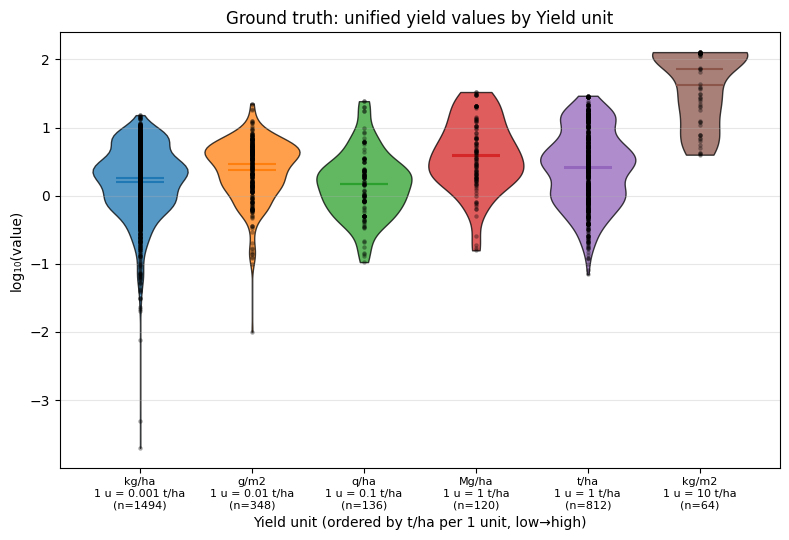

  (dropped 10 non-positive values for log₁₀ scale)


In [3]:
plot_violin_by_unit(
    yield_long,
    YIELD_UNIT_COL,
    title="Ground truth: unified yield values by Yield unit",
    xlabel="Yield unit (ordered by kg/ha per 1 unit, low→high)",
    kind="yield",
)

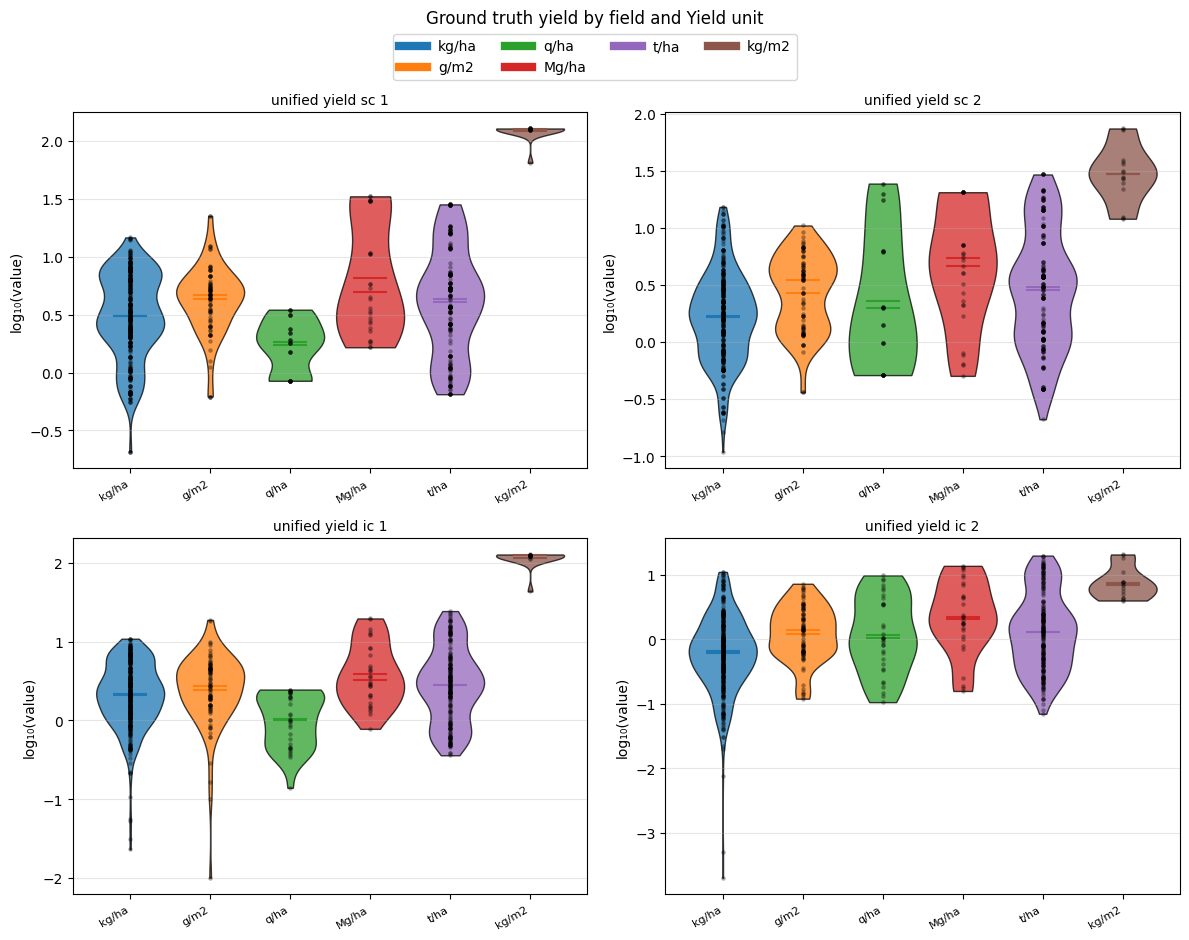

In [4]:
plot_violin_grid_by_field(
    yield_long,
    YIELD_UNIT_COL,
    YIELD_VALUE_COLS,
    title="Ground truth yield by field and Yield unit",
    kind="yield",
    ncols=2,
)

## N fertilizer (`N input *` vs `Unit.1`)

Values from all five N amount columns are pooled; color = `Unit.1`.

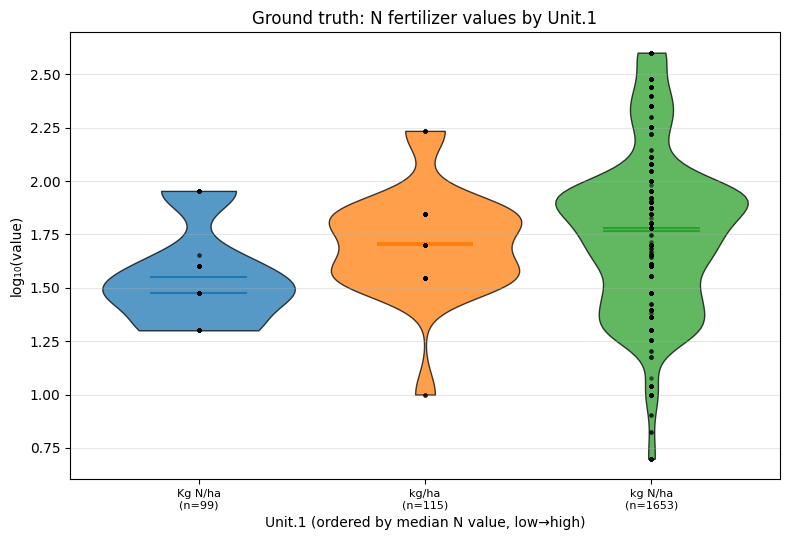

  (dropped 751 non-positive values for log₁₀ scale)


In [5]:
plot_violin_by_unit(
    n_long,
    N_UNIT_COL,
    title="Ground truth: N fertilizer values by Unit.1",
    xlabel="Unit.1 (all = 1× kg N/ha)",
    kind="n",
)

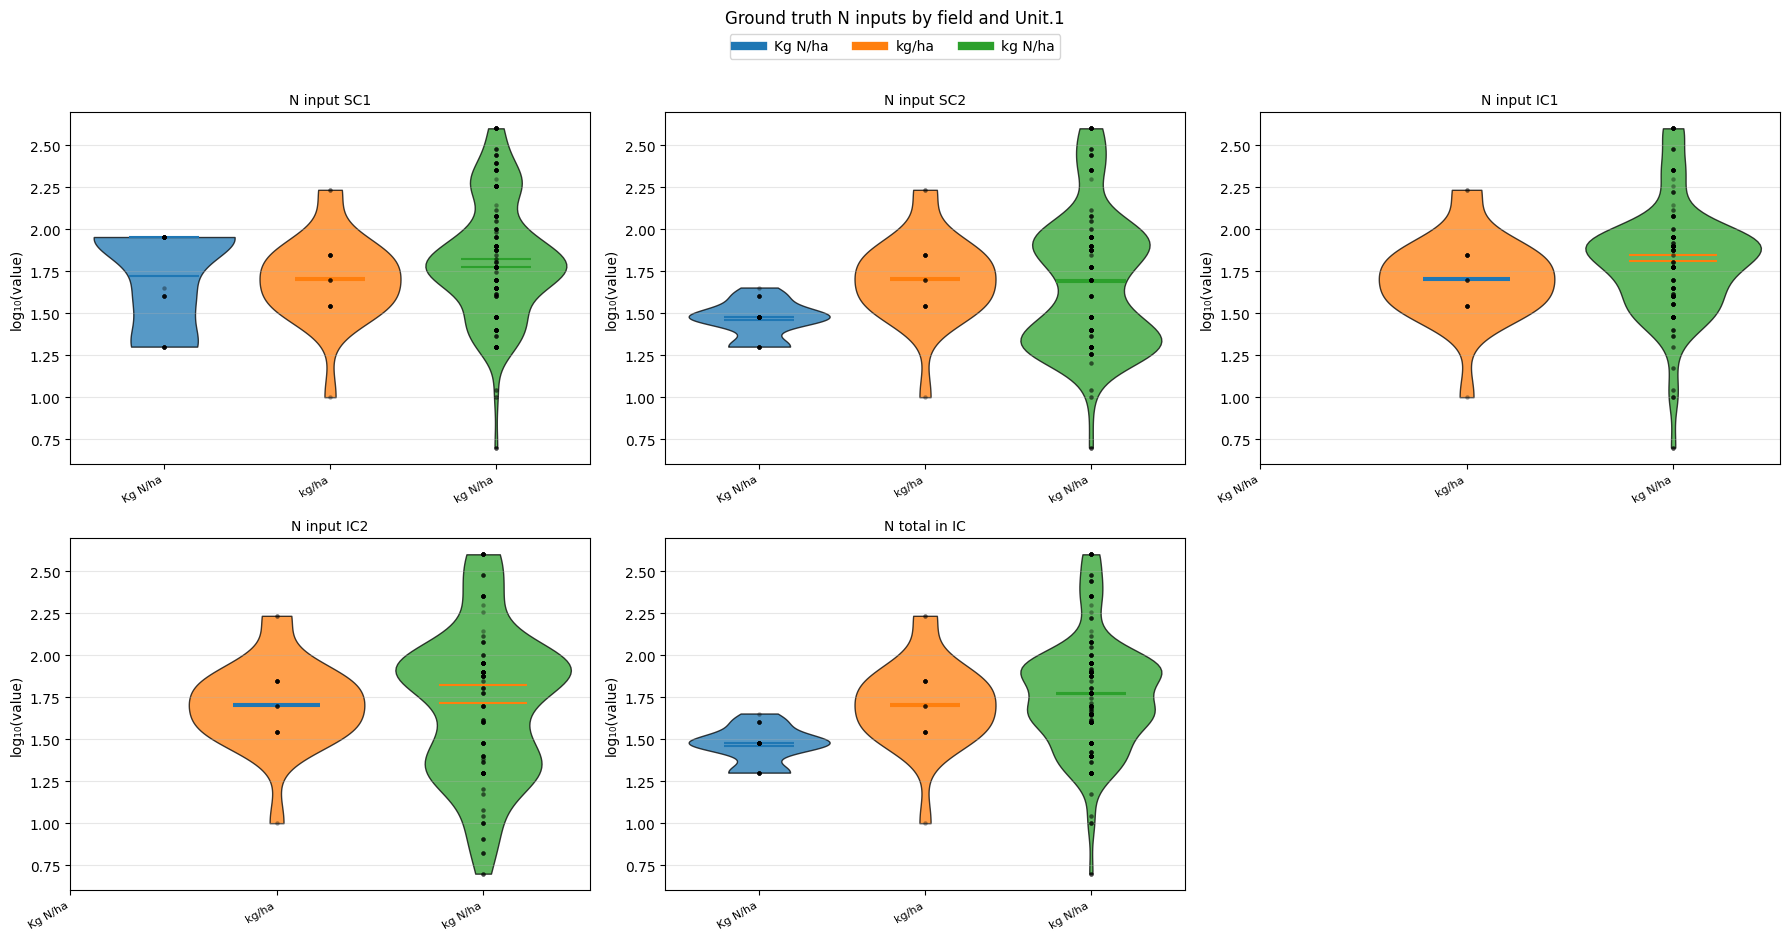

In [6]:
plot_violin_grid_by_field(
    n_long,
    N_UNIT_COL,
    N_VALUE_COLS,
    title="Ground truth N inputs by field and Unit.1",
    kind="n",
    ncols=3,
)